In [1]:
import pandas as pd

true_df = pd.read_csv("../data/raw/True.csv")
fake_df = pd.read_csv("../data/raw/Fake.csv")

print("True news shape:", true_df.shape)
print("Fake news shape:", fake_df.shape)


True news shape: (21417, 4)
Fake news shape: (23481, 4)


In [2]:
print("True News Columns:")
print(true_df.columns.tolist())

print("\nFake News Columns:")
print(fake_df.columns.tolist())

True News Columns:
['title', 'text', 'subject', 'date']

Fake News Columns:
['title', 'text', 'subject', 'date']


In [3]:
print("TRUE NEWS:")
display(true_df.head())

print("\nFAKE NEWS:")
display(fake_df.head())

TRUE NEWS:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"



FAKE NEWS:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
print("Missing values in True News:")
print(true_df.isnull().sum())

print("\nMissing values in Fake News:")
print(fake_df.isnull().sum())


Missing values in True News:
title      0
text       0
subject    0
date       0
dtype: int64

Missing values in Fake News:
title      0
text       0
subject    0
date       0
dtype: int64


In [5]:
print("Duplicate rows in True News:", true_df.duplicated().sum())
print("Duplicate rows in Fake News:", fake_df.duplicated().sum())


Duplicate rows in True News: 206
Duplicate rows in Fake News: 3


In [6]:
true_df["label"] = 1
fake_df["label"] = 0

print("True News:")
print(true_df["label"].value_counts())

print("\nFake News:")
print(fake_df["label"].value_counts())

True News:
label
1    21417
Name: count, dtype: int64

Fake News:
label
0    23481
Name: count, dtype: int64


Matplotlib is building the font cache; this may take a moment.


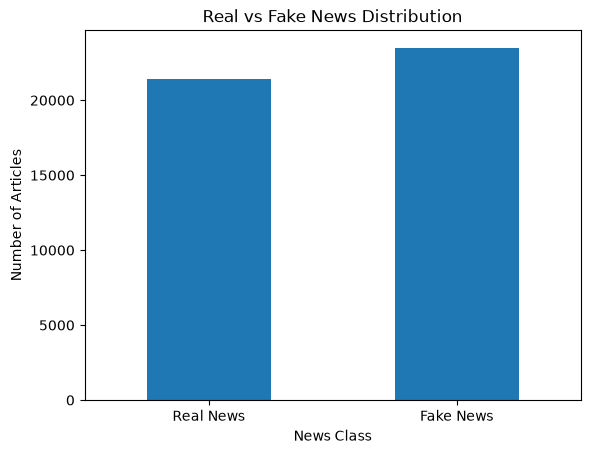

In [7]:
import matplotlib.pyplot as plt

label_counts = pd.Series({
    "Real News": len(true_df),
    "Fake News": len(fake_df)
})

label_counts.plot(kind="bar")

plt.title("Real vs Fake News Distribution")
plt.xlabel("News Class")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.show()

In [8]:
true_df["text_length"] = true_df["text"].str.len()
fake_df["text_length"] = fake_df["text"].str.len()

print("TRUE NEWS TEXT LENGTH")
print(true_df["text_length"].describe())

print("\nFAKE NEWS TEXT LENGTH")
print(fake_df["text_length"].describe())

TRUE NEWS TEXT LENGTH
count    21417.000000
mean      2383.278517
std       1684.835730
min          1.000000
25%        914.000000
50%       2222.000000
75%       3237.000000
max      29781.000000
Name: text_length, dtype: float64

FAKE NEWS TEXT LENGTH
count    23481.000000
mean      2547.396235
std       2532.884399
min          1.000000
25%       1433.000000
50%       2166.000000
75%       3032.000000
max      51794.000000
Name: text_length, dtype: float64


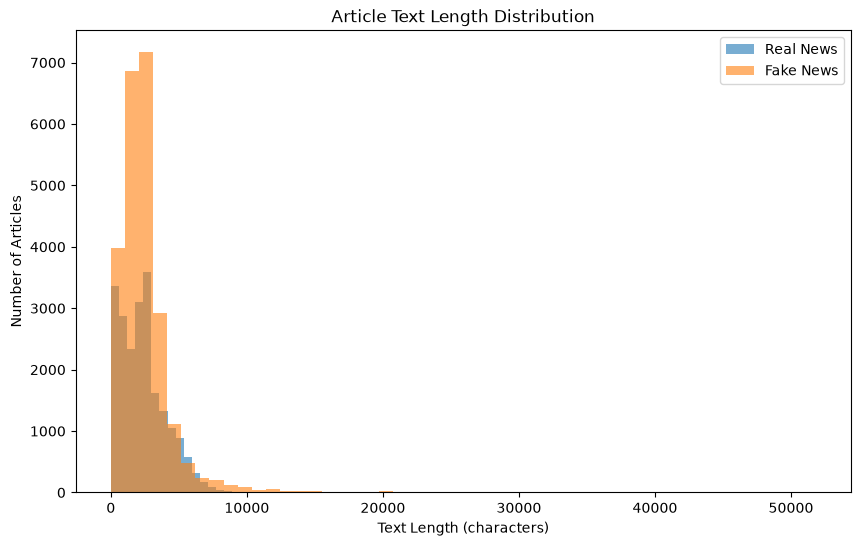

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(true_df["text_length"], bins=50, alpha=0.6, label="Real News")
plt.hist(fake_df["text_length"], bins=50, alpha=0.6, label="Fake News")

plt.title("Article Text Length Distribution")
plt.xlabel("Text Length (characters)")
plt.ylabel("Number of Articles")
plt.legend()
plt.show()


In [10]:
print("Very short TRUE articles:")
display(
    true_df[true_df["text_length"] <= 20][
        ["title", "text", "text_length"]
    ].head(10)
)

print("\nVery short FAKE articles:")
display(
    fake_df[fake_df["text_length"] <= 20][
        ["title", "text", "text_length"]
    ].head(10)
)


Very short TRUE articles:


,title,text,text_length
8970,Graphic: Supreme Court roundup,,1



Very short FAKE articles:


,title,text,text_length
10923,TAKE OUR POLL: Who Do You Think President Trum...,,1
11041,Joe Scarborough BERATES Mika Brzezinski Over “...,,1
11117,MY FAVORITE EXCUSES…Featuring Hillary Rotten C...,Enjoy:,6
11190,WATCH TUCKER CARLSON Scorch Sanctuary City May...,,1
11225,MAYOR OF SANCTUARY CITY: Trump Trying To Make ...,,1
11236,SHOCKER: Public School Turns Computer Lab Into...,,1
11241,BOOM! SEAN SPICER: “Trump Sold Hotels In Russi...,,1
11247,MICHAEL FLYNN’S LAWYER Releases Statement Scor...,,1
11249,ROB SCHNEIDER Nails The Russia Conspiracy Theo...,,1
11267,TREY GOWDY ON SPYING ON AMERICAN CITIZENS…Like...,,1


In [11]:
print("TRUE NEWS")
print("Text length <= 20:", (true_df["text_length"] <= 20).sum())

print("\nFAKE NEWS")
print("Text length <= 20:", (fake_df["text_length"] <= 20).sum())


TRUE NEWS
Text length <= 20: 1

FAKE NEWS
Text length <= 20: 672


In [12]:
print("TRUE NEWS")
print("Empty text:", (true_df["text"].str.strip() == "").sum())

print("\nFAKE NEWS")
print("Empty text:", (fake_df["text"].str.strip() == "").sum())

TRUE NEWS
Empty text: 1

FAKE NEWS
Empty text: 630


In [13]:
print("EMPTY TEXT — TRUE NEWS")
display(
    true_df[true_df["text"].str.strip() == ""][
        ["title", "subject", "date"]
    ]
)

print("\nEMPTY TEXT — FAKE NEWS")
display(
    fake_df[fake_df["text"].str.strip() == ""][
        ["title", "subject", "date"]
    ].head(20)
)

EMPTY TEXT — TRUE NEWS


,title,subject,date
8970,Graphic: Supreme Court roundup,politicsNews,"June 16, 2016"



EMPTY TEXT — FAKE NEWS


,title,subject,date
10923,TAKE OUR POLL: Who Do You Think President Trum...,politics,"May 10, 2017"
11041,Joe Scarborough BERATES Mika Brzezinski Over “...,politics,"Apr 26, 2017"
11190,WATCH TUCKER CARLSON Scorch Sanctuary City May...,politics,"Apr 6, 2017"
11225,MAYOR OF SANCTUARY CITY: Trump Trying To Make ...,politics,"Apr 2, 2017"
11236,SHOCKER: Public School Turns Computer Lab Into...,politics,"Apr 1, 2017"
11241,BOOM! SEAN SPICER: “Trump Sold Hotels In Russi...,politics,"Mar 31, 2017"
11247,MICHAEL FLYNN’S LAWYER Releases Statement Scor...,politics,"Mar 30, 2017"
11249,ROB SCHNEIDER Nails The Russia Conspiracy Theo...,politics,"Mar 30, 2017"
11267,TREY GOWDY ON SPYING ON AMERICAN CITIZENS…Like...,politics,"Mar 28, 2017"
11268,SEAN SPICER CALLS OUT Race Baiting Journalist:...,politics,"Mar 28, 2017"


In [14]:
print("TRUE NEWS SUBJECTS")
print(true_df["subject"].value_counts())

print("\nFAKE NEWS SUBJECTS")
print(fake_df["subject"].value_counts())


TRUE NEWS SUBJECTS
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64

FAKE NEWS SUBJECTS
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64


In [15]:
print("TRUE NEWS")
print("Total rows:", len(true_df))
print("Duplicate rows:", true_df.duplicated().sum())
print("Rows after removing duplicates:", len(true_df.drop_duplicates()))

print("\nFAKE NEWS")
print("Total rows:", len(fake_df))
print("Duplicate rows:", fake_df.duplicated().sum())
print("Rows after removing duplicates:", len(fake_df.drop_duplicates()))

TRUE NEWS
Total rows: 21417
Duplicate rows: 206
Rows after removing duplicates: 21211

FAKE NEWS
Total rows: 23481
Duplicate rows: 3
Rows after removing duplicates: 23478


In [16]:
true_df = true_df.drop_duplicates().reset_index(drop=True)
fake_df = fake_df.drop_duplicates().reset_index(drop=True)

print("Cleaned True News:", true_df.shape)
print("Cleaned Fake News:", fake_df.shape)

Cleaned True News: (21211, 6)
Cleaned Fake News: (23478, 6)


In [17]:
df = pd.concat([true_df, fake_df], ignore_index=True)

print("Combined dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())



Combined dataset shape: (44689, 6)

Class distribution:
label
0    23478
1    21211
Name: count, dtype: int64


In [18]:
print(df[["title", "label"]].head(10))

                                               title  label
0  As U.S. budget fight looms, Republicans flip t...      1
1  U.S. military to accept transgender recruits o...      1
2  Senior U.S. Republican senator: 'Let Mr. Muell...      1
3  FBI Russia probe helped by Australian diplomat...      1
4  Trump wants Postal Service to charge 'much mor...      1
5  White House, Congress prepare for talks on spe...      1
6  Trump says Russia probe will be fair, but time...      1
7  Factbox: Trump on Twitter (Dec 29) - Approval ...      1
8         Trump on Twitter (Dec 28) - Global Warming      1
9  Alabama official to certify Senator-elect Jone...      1


In [19]:
print("\nLast 10 rows:")
print(df[["title", "label"]].tail(10))


Last 10 rows:
                                                   title  label
44679  Seven Iranians freed in the prisoner swap have...      0
44680                      #Hashtag Hell & The Fake Left      0
44681  Astroturfing: Journalist Reveals Brainwashing ...      0
44682          The New American Century: An Era of Fraud      0
44683  Hillary Clinton: ‘Israel First’ (and no peace ...      0
44684  McPain: John McCain Furious That Iran Treated ...      0
44685  JUSTICE? Yahoo Settles E-mail Privacy Class-ac...      0
44686  Sunnistan: US and Allied ‘Safe Zone’ Plan to T...      0
44687  How to Blow $700 Million: Al Jazeera America F...      0
44688  10 U.S. Navy Sailors Held by Iranian Military ...      0


In [20]:
df["content"] = df["title"].fillna("") + " " + df["text"].fillna("")

print(df[["title", "text", "content", "label"]].head(3))

                                               title  \
0  As U.S. budget fight looms, Republicans flip t...   
1  U.S. military to accept transgender recruits o...   
2  Senior U.S. Republican senator: 'Let Mr. Muell...   

                                                text  \
0  WASHINGTON (Reuters) - The head of a conservat...   
1  WASHINGTON (Reuters) - Transgender people will...   
2  WASHINGTON (Reuters) - The special counsel inv...   

                                             content  label  
0  As U.S. budget fight looms, Republicans flip t...      1  
1  U.S. military to accept transgender recruits o...      1  
2  Senior U.S. Republican senator: 'Let Mr. Muell...      1  


In [21]:
# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset after shuffling:")
print(df[["title", "label"]].head(10))

print("\nClass distribution:")
print(df["label"].value_counts())

Dataset after shuffling:
                                               title  label
0  Merkel, Juncker discuss Catalan crisis: EU off...      1
1  LIBERAL HACK KATIE COURIC Says Fake News Is “T...      0
2  TRUMP WAS RIGHT! Audit Reveals State Dept. Cyb...      0
3   Clay Aiken Says He Was A ‘F*****g Dumbass’ Fo...      0
4  U.S. militia girds for trouble as presidential...      1
5           House to consider disaster aid Wednesday      1
6   CAN’T-MISS: Bernie And Hillary MOP The FLOOR ...      0
7   The IRS Already Commented On Trump’s Tax Retu...      0
8   Top Republican Operative Dubs Trump ‘Cheeto J...      0
9  MEET LEFTIST ANALYSTS At Research Firm Who Cre...      0

Class distribution:
label
0    23478
1    21211
Name: count, dtype: int64


In [22]:
print("Missing values:")
print(df[["content", "label"]].isnull().sum())

print("\nFinal dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

Missing values:
content    0
label      0
dtype: int64

Final dataset shape:
(44689, 7)

Columns:
['title', 'text', 'subject', 'date', 'label', 'text_length', 'content']


In [23]:
# Create final ML dataset
processed_df = df[["content", "label"]].copy()

# Save processed dataset
processed_df.to_csv("../data/processed/news_dataset.csv", index=False)

print("Processed dataset saved successfully!")
print("Shape:", processed_df.shape)
print("\nSaved columns:")
print(processed_df.columns.tolist())

Processed dataset saved successfully!
Shape: (44689, 2)

Saved columns:
['content', 'label']
